In [1]:
# Notebooks live in Notebooks/, but every data path is relative to the repo root.
import os, sys
while not os.path.isdir("data") and os.getcwd() != "/":
    os.chdir("..")
if os.getcwd() not in sys.path:
    sys.path.insert(0, os.getcwd())
print("cwd:", os.getcwd())

cwd: /home/lotan.amit/WhatDoLLMsWant


# Baseline BT weights — the three big models

The feature BT weights with **no contract** (frame `shopping`, 45 laptops, 5 templates) for the biggest
model of each family: qwen-72B, gemma-27B, olmo-32B. Same style as figure A of `figs4nir2`.

Weights are centred to mean 0 inside each feature, so a bar reads "above / below the average level".
Each panel has **its own y-axis**: the size of the weights is not comparable between models
(status point 10), only the shape is.

In [2]:
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.bt import FeatureBT

SURFACE, INK, INK_MUTED = "#fcfcfb", "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "axes.edgecolor": "#d6d5d1",
    "axes.labelcolor": INK, "axes.titlecolor": INK, "text.color": INK,
    "xtick.color": INK_MUTED, "ytick.color": INK_MUTED, "axes.grid": False,
    "axes.spines.top": False, "axes.spines.right": False, "figure.dpi": 110, "font.size": 10,
    "savefig.bbox": "tight", "savefig.dpi": 200,
})
FIGDIR = "figs/baseline_weights_big3"
os.makedirs(FIGDIR, exist_ok=True)

BRANDS = ["ASUS", "Apple", "Dell", "HP", "Lenovo"]
SCREEN, RAM = ["13-inch", "14-inch", "16-inch"], ["4GB", "8GB", "16GB"]
FEATS = ["brand", "screen", "ram"]
LEVELS = {"brand": BRANDS, "screen": SCREEN, "ram": RAM}
FEATURE_COLOR = {"brand": "#6aa83f", "screen": "#c75f8b", "ram": "#4c8fd4"}   # same colours as figs4nir2
LV = [(f, l) for f in FEATS for l in LEVELS[f]]
LABEL = {l: l.replace("-inch", '"') for _, l in LV}

# the instruct runs of each family sit in a different folder
MODELS = [("qwen", "72"), ("gemma", "27"), ("olmo", "32")]
FOLDER = {"qwen": "data/laptops_robustness", "gemma": "data/laptops_robustness_gemma", "olmo": "data/laptops_olmo"}

## Load the three runs and fit

In [3]:
def baseline_run(model):
    """The one complete no-contract `shopping` run of this model -> (run id, scores)."""
    folder, out = FOLDER[model[0]], []
    for r in sorted(os.listdir(folder)):
        cf, sc = f"{folder}/{r}/config.json", f"{folder}/{r}/scores.csv"
        if not (os.path.isfile(cf) and os.path.isfile(sc)):
            continue                                   # config without scores = a dead run
        c = json.load(open(cf))
        if ((c["model_family"], str(c["model_size"])) == model and c["frame"]["name"] == "shopping"
                and c["constraints"] == {}):
            out.append((r, pd.read_csv(sc)))
    assert len(out) == 1, (model, [r for r, _ in out])
    assert len(out[0][1]) == 9900
    return out[0]


W, INFO = {}, []
for m in MODELS:
    run, d = baseline_run(m)
    bt = FeatureBT(r2_warn=None).fit(d)
    name = f"{m[0]}-{m[1]}B"
    W[name] = pd.Series({l: bt.weights_[f][l] for f, l in LV})
    INFO.append({"model": name, "run": f"{FOLDER[m[0]]}/{run}", "rows": len(d), "R2": bt.r2_,
                 "beta0": bt.beta0_, "S (total spread)": bt.total_spread(),
                 **{f"range {f}": bt.range(f) for f in FEATS}})

W = pd.DataFrame(W)
W.index = pd.MultiIndex.from_tuples(LV, names=["feature", "level"])
W.to_csv(os.path.join(FIGDIR, "baseline_weights.csv"))
display(pd.DataFrame(INFO).set_index("model").round(2))
display(W.round(2))

,run,rows,R2,beta0,S (total spread),range brand,range screen,range ram
model,,,,,,,,
qwen-72B,data/laptops_robustness/1271581,9900,0.86,-9.44,32.49,2.84,4.26,25.39
gemma-27B,data/laptops_robustness_gemma/68378741,9900,0.79,-7.83,42.59,4.88,6.78,30.93
olmo-32B,data/laptops_olmo/1319097,9900,0.91,-0.87,9.27,0.29,0.49,8.49


qwen-72B  gemma-27B  olmo-32B
feature level                                 
brand   ASUS        -0.33       0.18      0.14
        Apple        1.95       2.74     -0.13
        Dell         0.16      -0.98      0.16
        HP          -0.90      -2.14     -0.13
        Lenovo      -0.89       0.19     -0.03
screen  13-inch     -2.16      -3.21     -0.27
        14-inch      0.07      -0.37      0.06
        16-inch      2.09       3.57      0.21
ram     4GB        -13.10     -15.75     -4.68
        8GB          0.82       0.57      0.86
        16GB        12.29      15.18      3.82

## The figure

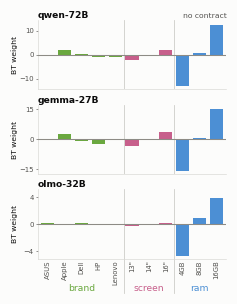

In [4]:
def nice_tick(v):
    """Biggest round number that is not above v."""
    return max(t for t in [0.5, 1, 2, 4, 5, 10, 15, 20, 30] if t <= v)


def fig_weights():
    names = list(W.columns)
    fig, axes = plt.subplots(len(names), 1, figsize=(2, 0.875 * len(names)), sharex=True)
    x = np.arange(len(LV))
    for ax, name in zip(axes, names):
        w = W[name].values
        top = np.abs(w).max()
        ax.bar(x, w, 0.78, color=[FEATURE_COLOR[f] for f, _ in LV], zorder=2)
        ax.axhline(0, color="#8d8b85", lw=0.7, zorder=3)
        ax.set_title(name, loc="left", fontsize=6, fontweight="bold", pad=1.5)
        ax.set_ylabel("BT weight", fontsize=5, labelpad=1)
        ax.set_ylim(-1.1 * top, 1.1 * top)                 # own scale per model
        t = nice_tick(top)
        ax.set_yticks([-t, 0, t])
        ax.tick_params(axis="y", labelsize=4.5, length=1.5, width=0.4, pad=1, colors=INK_MUTED)
        ax.tick_params(axis="x", length=0, pad=1)
        ax.spines["left"].set_linewidth(0.4)
        ax.spines["bottom"].set_linewidth(0.4)
        ax.set_xlim(-0.6, len(LV) - 0.4)
    axes[0].text(1, 1.02, "no contract", transform=axes[0].transAxes, ha="right", va="bottom", fontsize=5,
                 color=INK_MUTED)
    axes[-1].set_xticks(x, [LABEL[l] for _, l in LV], rotation=90, fontsize=4.5, color=INK_MUTED)
    fig.tight_layout(h_pad=0.4, pad=0.15, rect=(0, 0.035, 1, 1))
    fig.align_ylabels(axes)
    for k in (5, 8):
        for ax in axes:
            ax.axvline(k - 0.5, color="#c9c8c3", lw=0.5, zorder=1)
        axes[-1].plot([k - 0.5, k - 0.5], [0, -0.5], transform=axes[-1].get_xaxis_transform(), color="#c9c8c3",
                      lw=0.5, clip_on=False)
    for f, (a, b) in zip(FEATS, [(0, 4), (5, 7), (8, 10)]):
        axes[-1].text((a + b) / 2, -0.43, f, transform=axes[-1].get_xaxis_transform(), ha="center",
                      va="center", fontsize=6, color=FEATURE_COLOR[f])
    fig.savefig(os.path.join(FIGDIR, "baseline_weights_big3.png"), facecolor=SURFACE, dpi=400)
    fig.savefig(os.path.join(FIGDIR, "baseline_weights_big3.pdf"), facecolor=SURFACE)
    plt.show()


fig_weights()